In [2]:
import os
import sys
from typing import Dict, Any
import itertools

import json
import pandas as pd
import numpy as np
import evaluate
from tqdm import tqdm
import seaborn as sns
from bert_score import BERTScorer
import matplotlib.pyplot as plt
from scipy.stats import mannwhitneyu
import torch

sys.path.append(f"{os.environ['MDS']}/code")
from project_utils import load_config

pd.set_option('display.precision', 2)

/home/adeluci2/.conda/envs/mds/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


# Objective

Demonstrate stylistic differences between summarization datasets quantitatively.

## Hypothesis:

**H1:** The average intra-dataset similarity will be significantly higher than the average inter-dataset similarity for both source documents and reference summaries. This would confirm that each domain has a distinct, measurable style that models can overfit to.

**H0 (Null):** There will be no significant difference between intra- and inter-dataset similarity, suggesting domains are not stylistically distinct.

## Plan

For each dataset (News, Science, Conversation), calculate the average intra-dataset similarity for both source document sets and reference summaries. This measures how stylistically consistent each domain is.

For each pair of datasets (e.g., News vs. Science), calculate the average inter-dataset similarity for source documents and reference summaries. This measures how stylistically different the domains are from each other.

A suitable metric like ROUGE-L or BERTScore can be used for this analysis.

# Calculate Similarity

09/27/2025 19:23:58 - WARNING - Using the latest cached version of the module from /scratch4/mdredze1/huggingface_cache/modules/evaluate_modules/metrics/evaluate-metric--rouge/b01e0accf3bd6dd24839b769a5fda24e14995071570870922c71970b3a6ed886 (last modified on Tue Apr 22 14:46:24 2025) since it couldn't be found locally at evaluate-metric--rouge, or remotely on the Hugging Face Hub.
--- Using metric: rouge ---

Loading datasets...
Data loading complete.

Sampling 100 instances from each dataset...

Calculating all pairwise similarity distributions...
  - Calculating intra-similarity for convosumm/reddit...
09/27/2025 19:24:00 - INFO - Using default tokenizer.


/tmp/ipykernel_1572328/3786278527.py:60: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  sampled_df = dataset_df.groupby('dataset', group_keys=False).apply(sample_group)


  - Calculating inter-similarity for convosumm/reddit vs multinews_plus...
09/27/2025 19:24:37 - INFO - Using default tokenizer.
  - Calculating inter-similarity for convosumm/reddit vs multixscience...
09/27/2025 19:26:18 - INFO - Using default tokenizer.
  - Calculating intra-similarity for multinews_plus...
09/27/2025 19:27:15 - INFO - Using default tokenizer.
  - Calculating inter-similarity for multinews_plus vs convosumm/reddit...
09/27/2025 19:31:33 - INFO - Using default tokenizer.
  - Calculating inter-similarity for multinews_plus vs multixscience...
09/27/2025 19:33:13 - INFO - Using default tokenizer.
  - Calculating intra-similarity for multixscience...
09/27/2025 19:35:43 - INFO - Using default tokenizer.
  - Calculating inter-similarity for multixscience vs convosumm/reddit...
09/27/2025 19:37:07 - INFO - Using default tokenizer.
  - Calculating inter-similarity for multixscience vs multinews_plus...
09/27/2025 19:38:04 - INFO - Using default tokenizer.
All similarity ca

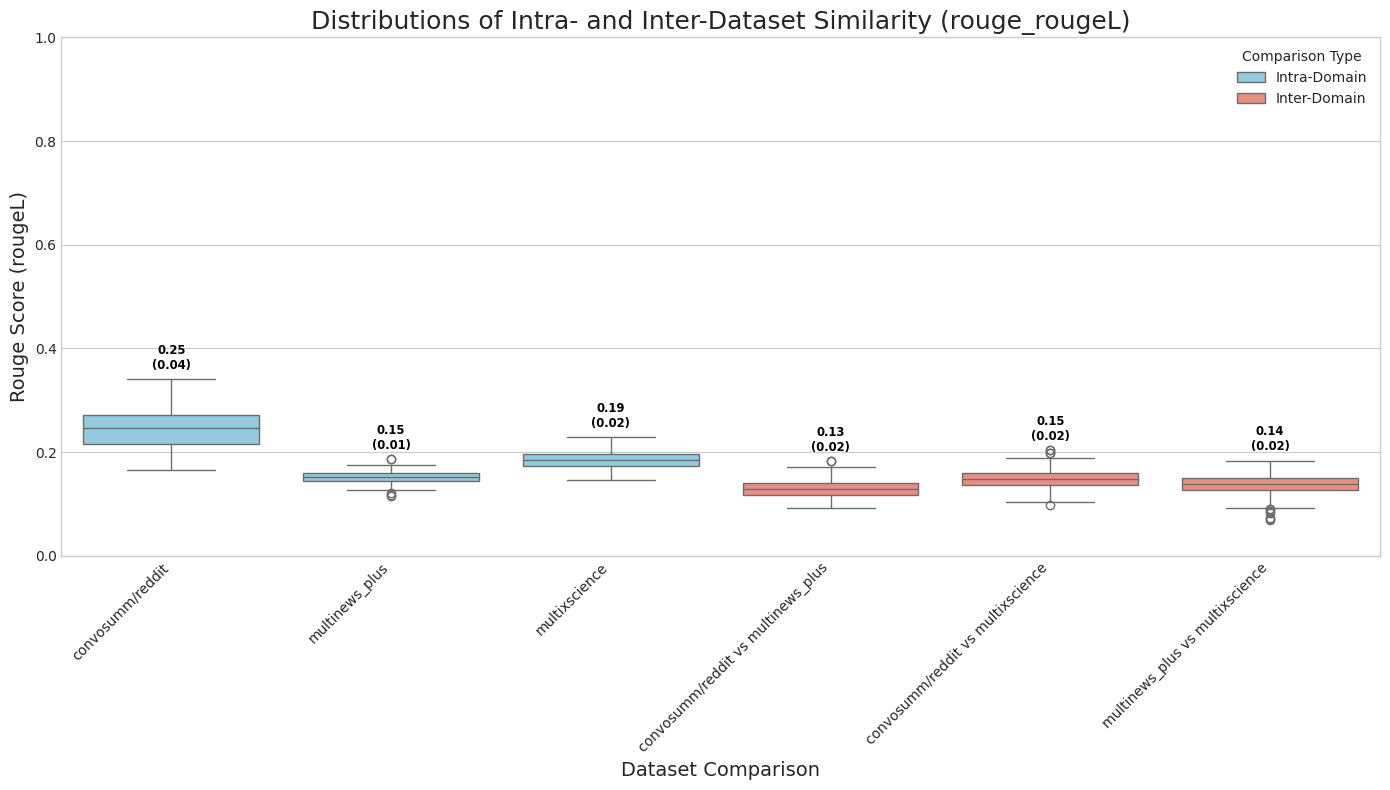

In [3]:
# --- 1. Core Configuration ---
SAMPLE_SIZE = 100
RANDOM_STATE = 42
METRIC_TO_USE = 'rouge'  # <-- CHANGE THIS to 'rouge' or 'bertscore'

# --- Metric-Specific Settings ---
METRIC_CONFIG = {
    'rouge': {
        'scorer': evaluate.load('rouge'),
        'plot_key': 'rougeL', # The specific score to use for plots
        'agg_params': {'use_stemmer': True}
    },
    'bertscore': {
        'scorer': None, # Scorer will be loaded below
        'plot_key': 'f1',
        'agg_params': {
            'model_type': 'microsoft/deberta-xlarge-mnli',
            'lang': 'en',
        }
    }
}

# --- 2. Load the Selected Metric Scorer ---
print(f"--- Using metric: {METRIC_TO_USE} ---")
scorer = METRIC_CONFIG[METRIC_TO_USE]['scorer']
plot_key = METRIC_CONFIG[METRIC_TO_USE]['plot_key']
agg_params = METRIC_CONFIG[METRIC_TO_USE]['agg_params']
column_name_key = f"{METRIC_TO_USE}_{plot_key}"

if METRIC_TO_USE == 'bertscore':
    device = 'cuda' if torch.cuda.is_available() else 'cpu'
    print(f"Loading BERTScorer on device: {device}")
    scorer = BERTScorer(device=device, **agg_params)

# --- 3. Load Data ---
with open(f"{os.environ['MDS']}/code/experiments_mayarr.json") as f:
    experiments_config = json.load(f)

dataset_dfs = []
print("\nLoading datasets...")
for dataset in experiments_config["datasets"]:
    filepath = f"{os.environ['MDS']}/data/{dataset}/test.jsonl"
    if os.path.exists(filepath):
        df = pd.read_json(filepath, lines=True)
        df["dataset"] = dataset
        dataset_dfs.append(df)
    else:
        print(f"Warning: File not found at {filepath}")

if not dataset_dfs:
    raise FileNotFoundError("No dataset files were found.")
dataset_df = pd.concat(dataset_dfs, ignore_index=True)
print("Data loading complete.")

# --- 4. Sample the DataFrame ---
print(f"\nSampling {SAMPLE_SIZE} instances from each dataset...")
def sample_group(group):
    n_samples = min(len(group), SAMPLE_SIZE)
    return group.sample(n=n_samples, random_state=RANDOM_STATE)
sampled_df = dataset_df.groupby('dataset', group_keys=False).apply(sample_group)


# --- 5. Define Generic Similarity Calculation ---
def compute_scores(predictions, references):
    """Generic wrapper to compute scores for either metric, always per-item."""
    if METRIC_TO_USE == 'rouge':
        results = scorer.compute(predictions=predictions, references=references, use_aggregator=False, **agg_params)
        return results[plot_key] # Return the list of scores for the desired key
    elif METRIC_TO_USE == 'bertscore':
        p, r, f1 = scorer.score(predictions, references)
        return f1.tolist() # Return the list of F1 scores

# --- 6. Calculate All Pairwise Similarity Distributions ---
print("\nCalculating all pairwise similarity distributions...")
all_datasets = sampled_df['dataset'].unique()
all_results = []

for d1 in all_datasets:
    # Intra-dataset calculation
    print(f"  - Calculating intra-similarity for {d1}...")
    summaries_d1 = sampled_df[sampled_df['dataset'] == d1]['target'].tolist()
    if len(summaries_d1) > 1:
        references = [summaries_d1[:i] + summaries_d1[i+1:] for i in range(len(summaries_d1))]
        scores = compute_scores(summaries_d1, references)
        for score in scores:
            all_results.append({
                'score': score,
                'comparison': f"{d1}",
                'type': 'Intra-Domain'
            })

    # Inter-dataset calculations
    for d2 in all_datasets:
        if d1 == d2:
            continue
        print(f"  - Calculating inter-similarity for {d1} vs {d2}...")
        summaries_d2 = sampled_df[sampled_df['dataset'] == d2]['target'].tolist()
        if summaries_d1 and summaries_d2:
            # Compare each summary in d1 to ALL summaries in d2
            references = [summaries_d2] * len(summaries_d1)
            scores = compute_scores(summaries_d1, references)
            pair_name = " vs ".join(sorted([d1, d2]))
            for score in scores:
                all_results.append({
                    'score': score,
                    'comparison': pair_name,
                    'type': 'Inter-Domain'
                })

dist_df = pd.DataFrame(all_results)
print("All similarity calculations complete.")


# --- 7. Create Distribution Visualization (Violin Plot) ---
print("\nGenerating distribution plot...")
plt.style.use('seaborn-v0_8-whitegrid')
fig, ax = plt.subplots(figsize=(14, 8))

# Order the comparisons for a clean plot
order = sorted(dist_df[dist_df['type'] == 'Intra-Domain']['comparison'].unique()) + \
        sorted(dist_df[dist_df['type'] == 'Inter-Domain']['comparison'].unique())

sns.boxplot(
    data=dist_df,
    x='comparison',
    y='score',
    hue='type',
    palette={'Intra-Domain': 'skyblue', 'Inter-Domain': 'salmon'},
    ax=ax,
    order=order,
    dodge=False # Prevent dodging for single intra-domain boxes
)

# Calculate means and stds for each box
box_stats = dist_df.groupby('comparison')['score'].agg(['mean', 'std']).reindex(order)

for i, comparison in enumerate(order):
    stats = box_stats.loc[comparison]
    mean_val = stats['mean']
    std_val = stats['std']
    
    annotation_text = f"{mean_val:.2f}\n({std_val:.2f})"
    
    # Place text slightly above the maximum value for that group
    y_pos = dist_df[dist_df['comparison'] == comparison]['score'].max() + 0.02
    
    ax.text(
        i, y_pos, annotation_text,
        horizontalalignment='center', size='small',
        color='black', weight='semibold'
    )

ax.set_title(f'Distributions of Intra- and Inter-Dataset Similarity ({column_name_key})', fontsize=18)
ax.set_xlabel('Dataset Comparison', fontsize=14)
ax.set_ylabel(f'{METRIC_TO_USE.title()} Score ({plot_key})', fontsize=14)
plt.setp(ax.get_xticklabels(), rotation=45, horizontalalignment='right')
ax.set_ylim(0, 1)
ax.legend(title='Comparison Type')

plt.tight_layout()
plt.savefig(f"similarity_distributions_{column_name_key}.png", dpi=300)
print(f"Distribution plot saved to similarity_distributions_{column_name_key}.png")
plt.show()


In [4]:
# --- 8. Perform Statistical Significance Test ---
print("\n--- Statistical Significance Analysis ---")
intra_scores = dist_df[dist_df['type'] == 'Intra-Domain']['score']
inter_scores = dist_df[dist_df['type'] == 'Inter-Domain']['score']

print(f"Comparing {len(intra_scores)} intra-domain scores against {len(inter_scores)} inter-domain scores.")

# Perform the Mann-Whitney U test
if len(intra_scores) > 0 and len(inter_scores) > 0:
    u_statistic, p_value = mannwhitneyu(intra_scores, inter_scores, alternative='two-sided')

    print(f"\nMann-Whitney U Test Results ({METRIC_TO_USE}):")
    print(f"U-statistic: {u_statistic:.2f}")
    print(f"P-value: {p_value}")

    # Interpretation
    alpha = 0.05
    if p_value < alpha:
        print(f"\nConclusion: The p-value is less than {alpha}, so we reject the null hypothesis.")
        print("There is a statistically significant difference between the intra-domain and inter-domain similarity scores.")
    else:
        print(f"\nConclusion: The p-value is greater than {alpha}, so we fail to reject the null hypothesis.")
        print("There is no statistically significant difference between the intra-domain and inter-domain similarity scores.")
else:
    print("Could not perform statistical test: one or both groups have no data.")



--- Statistical Significance Analysis ---
Comparing 300 intra-domain scores against 600 inter-domain scores.

Mann-Whitney U Test Results (rouge):
U-statistic: 159618.50
P-value: 5.637672360415019e-80

Conclusion: The p-value is less than 0.05, so we reject the null hypothesis.
There is a statistically significant difference between the intra-domain and inter-domain similarity scores.


In [5]:
dist_df

,score,comparison,type
0,0.34,convosumm/reddit,Intra-Domain
1,0.26,convosumm/reddit,Intra-Domain
2,0.30,convosumm/reddit,Intra-Domain
3,0.19,convosumm/reddit,Intra-Domain
4,0.24,convosumm/reddit,Intra-Domain
...,...,...,...
895,0.15,multinews_plus vs multixscience,Inter-Domain
896,0.09,multinews_plus vs multixscience,Inter-Domain
897,0.18,multinews_plus vs multixscience,Inter-Domain
898,0.15,multinews_plus vs multixscience,Inter-Domain


In [6]:
dist_df.groupby(["comparison"]).agg({"score": ["mean", "std"]})

score      
                                    mean   std
comparison                                    
convosumm/reddit                    0.25  0.04
convosumm/reddit vs multinews_plus  0.13  0.02
convosumm/reddit vs multixscience   0.15  0.02
multinews_plus                      0.15  0.01
multinews_plus vs multixscience     0.14  0.02
multixscience                       0.19  0.02